# Copia de consulta — no editar ni usar para entrenar

Original: `notebooks/15_comparacion_validacion.ipynb` · SHA-256 (UTF-8, saltos LF): `9926b9d563ec9d0b62dcc4d868798411ce91bb50d48931018e4369c29e5f090c`.

Tipo: **ejecucion_completa**. Fecha de ejecución/consulta: 2026-11-10T03:26:33.159909+00:00. Commit de ejecución: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Entorno de ejecución: `{"Pillow": "12.1.1", "figure_dpi": 55, "matplotlib": "3.10.8", "nbclient": "0.10.4", "numpy": "1.26.4", "pandas": "2.2.2", "python": "3.11.9", "scikit-learn": "1.7.2", "sistema": "Windows-10-10.0.26200-SP0"}`. Publicación: 2026-11-10T00:36:01-03:00. Commit de referencia del código: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Preparación del insumo: sin celdas omitidas.

Celdas ejecutadas (índices del original): [2, 4, 6, 8, 10, 12, 14]. Familia del test: no aplica.

Una consulta de corridas guardadas muestra resultados reales ya existentes; no reproduce los logs del entrenamiento. Val eligió checkpoints y se usa para reportar. Se quitaron widgets y formatos activos; en test se quitaron todas las imágenes.


<a href="https://colab.research.google.com/github/candeperles/PDI-TP/blob/main/notebooks/15_comparacion_validacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 15. Comparación en validación

Junta todas las corridas del equipo guardadas en `Mi unidad/PDI-TP/resultados/` y las compara sobre las mismas
162 imágenes de val y sobre las 23 de Jamaica (el test va a ser de Kingston). **No entrena nada**: abre los
resultados en solo lectura (`entorno.preparar(solo_lectura=True)`), así que no puede crear ni modificar nada en
Drive.

Entran en la comparación:

- **Clasificadores**: MobileNetV2, ResNet50 y EfficientNetB0 en sus tres modos, **solo las corridas con la receta
  común vigente** (`receta: "comun_v2"` en `config.json`). Las de recetas anteriores se listan pero no se comparan.
- **Detectores usados como clasificadores**: YOLOv8n y YOLO11n. El puntaje de cada imagen es la máxima confianza
  de sus cajas, con umbral 0.25.
- **Referencia**: el clasificador trivial que siempre dice "con paneles".

**Cómo leer los números:**

1. **Val también eligió los checkpoints**, así que todas las métricas son optimistas. Decirlo en el informe.
2. **Cada métrica va con un intervalo de 95 %** por bootstrap (se remuestrean las imágenes de val). Con 20
   imágenes sin paneles en val y 23 de Jamaica, una sola imagen mueve mucho las métricas.
3. **Una diferencia entre dos corridas es clara solo si su intervalo no incluye el 0.** Las diferencias se miden
   pareadas: las dos corridas sobre las mismas imágenes remuestreadas.
4. **Para comparar CNN contra detector, mirar sobre todo el AUC**: no depende del umbral, y el puntaje de YOLO no
   es una probabilidad calibrada.

Correr en Colab (no hace falta GPU) con *Ejecutar todas*. Se puede volver a correr cada vez que haya corridas
nuevas.

In [1]:
# --- Setup: correr siempre primero ---
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/PDI-TP")
    if repo.is_dir():
        subprocess.run(["git", "-C", str(repo), "pull", "--ff-only", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/candeperles/PDI-TP.git", str(repo)], check=True)
else:
    # Funciona al abrir Jupyter desde la raíz o desde notebooks/.
    repo = next((p for p in (Path.cwd(), Path.cwd().parent)
                 if (p / "pdi_tp" / "entorno.py").is_file()), None)
    if repo is None:
        raise FileNotFoundError("Abrí Jupyter desde la raíz del repositorio o desde notebooks/.")
os.chdir(repo)
sys.path.insert(0, str(repo))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pdi_tp import comparacion, entorno, resultados

rutas = entorno.preparar(solo_lectura=True)  # monta Drive, pero no deja crear ni guardar corridas

Dataset:    C:\Users\cande\PDI-TP\data\grupo_5 (900 imágenes)
Resultados: C:\Users\cande\PDI-TP\resultados_locales\resultados (se crea al guardar un modelo)
GPU:        no hay GPU NVIDIA (corriendo en local)


## 1. Qué corridas entran

`vigente` indica si la corrida entra en la comparación. Si falta alguna de las esperadas, todavía no se corrió (o
quedó incompleta) con la receta actual: la comparación se hace igual con las que hay.

In [2]:
ESPERADAS = [f"{m}/{modo}" for m in ("mobilenetv2", "resnet50", "efficientnetb0")
             for modo in ("imagenet_congelado", "imagenet_finetuning", "aleatorio")]
ESPERADAS += [f"{m}/{modo}" for m in ("yolov8n", "yolo11n", "yolo26n") for modo in ("coco_completo", "coco_backbone_congelado")]

corridas = comparacion.corridas_vigentes(resultados.cargar_corridas(rutas))
ELEGIDAS = corridas.loc[corridas["vigente"], "corrida"].tolist()
FAMILIA = dict(zip(corridas["corrida"], corridas["familia"]))

print(f"Receta vigente de las CNN: {comparacion.RECETA_VIGENTE}")
print("Entran:", len(ELEGIDAS))
faltan = [c for c in ESPERADAS if c not in ELEGIDAS]
print("Faltan (no corridas o con otra receta):", faltan or "ninguna")
viejas = corridas.loc[~corridas["vigente"], "corrida"].tolist()
print("Corridas con otra receta, que no se comparan:", viejas or "ninguna")
corridas[["corrida", "familia", "receta", "vigente", "umbral", "fecha"]]

Receta vigente de las CNN: comun_v2
Entran: 15
Faltan (no corridas o con otra receta): ninguna
Corridas con otra receta, que no se comparan: ninguna


,corrida,familia,receta,vigente,umbral,fecha
0,efficientnetb0/aleatorio,clasificador,comun_v2,True,0.50,2026-11-02T20:00:36
1,efficientnetb0/imagenet_congelado,clasificador,comun_v2,True,0.50,2026-11-02T19:49:53
2,efficientnetb0/imagenet_finetuning,clasificador,comun_v2,True,0.50,2026-11-02T19:54:06
3,mobilenetv2/aleatorio,clasificador,comun_v2,True,0.50,2026-11-02T19:49:53
4,mobilenetv2/imagenet_congelado,clasificador,comun_v2,True,0.50,2026-11-02T19:41:13
5,mobilenetv2/imagenet_finetuning,clasificador,comun_v2,True,0.50,2026-11-02T19:45:41
6,resnet50/aleatorio,clasificador,comun_v2,True,0.50,2026-11-03T17:15:17
7,resnet50/imagenet_congelado,clasificador,comun_v2,True,0.50,2026-11-03T16:46:40
8,resnet50/imagenet_finetuning,clasificador,comun_v2,True,0.50,2026-11-03T16:52:43
9,yolo11n/coco_backbone_congelado,detector,NaN,True,0.25,2026-11-02T20:48:04


## 2. Val: las 162 imágenes

Ordenadas por **F1 macro** (el criterio de los notebooks de clasificación): le da el mismo peso a la clase *sin
paneles*, así que el clasificador trivial queda abajo. Entre corchetes, el intervalo de 95 %.

Val: 162 imágenes, 20 sin paneles. Val también eligió los checkpoints: números optimistas.


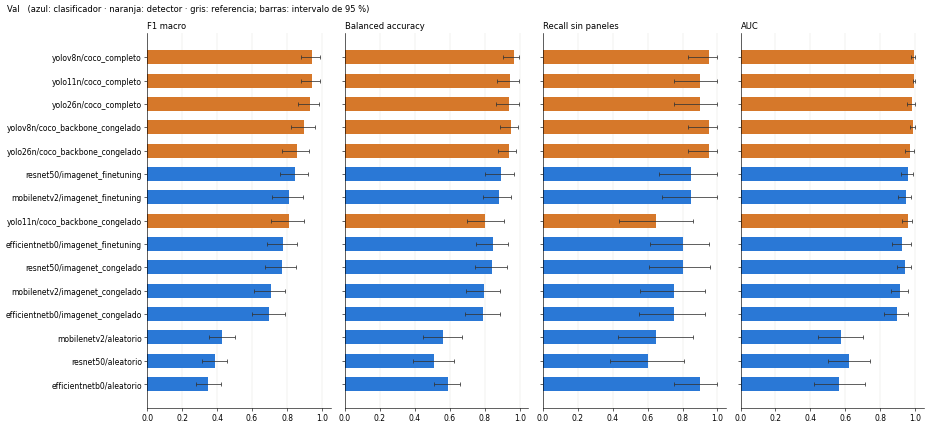

,familia,F1 macro,Balanced accuracy,Recall sin paneles,AUC
corrida,,,,,
yolov8n/coco_completo,detector,"0.945 [0.882, 0.988]","0.964 [0.905, 0.997]","0.950 [0.833, 1.000]","0.992 [0.977, 1.000]"
yolo11n/coco_completo,detector,"0.943 [0.881, 0.988]","0.943 [0.868, 0.997]","0.900 [0.750, 1.000]","0.995 [0.987, 1.000]"
yolo26n/coco_completo,detector,"0.930 [0.863, 0.984]","0.939 [0.865, 0.993]","0.900 [0.750, 1.000]","0.980 [0.954, 0.999]"
yolov8n/coco_backbone_congelado,detector,"0.899 [0.821, 0.961]","0.950 [0.890, 0.989]","0.950 [0.833, 1.000]","0.986 [0.969, 0.998]"
yolo26n/coco_backbone_congelado,detector,"0.858 [0.772, 0.927]","0.936 [0.875, 0.977]","0.950 [0.833, 1.000]","0.971 [0.943, 0.993]"
resnet50/imagenet_finetuning,clasificador,"0.848 [0.757, 0.921]","0.893 [0.803, 0.968]","0.850 [0.667, 1.000]","0.957 [0.917, 0.987]"
mobilenetv2/imagenet_finetuning,clasificador,"0.811 [0.716, 0.889]","0.879 [0.792, 0.952]","0.850 [0.684, 1.000]","0.945 [0.903, 0.977]"
yolo11n/coco_backbone_congelado,detector,"0.811 [0.707, 0.899]","0.804 [0.697, 0.907]","0.650 [0.438, 0.857]","0.958 [0.924, 0.984]"
efficientnetb0/imagenet_finetuning,clasificador,"0.779 [0.684, 0.858]","0.847 [0.749, 0.932]","0.800 [0.611, 0.952]","0.927 [0.864, 0.975]"


In [3]:
COLORES = {"clasificador": "#2a78d6", "detector": "#d6782a", "referencia": "#9a9a94"}
TITULOS = {"f1_macro": "F1 macro", "balanced_accuracy": "Balanced accuracy",
           "recall_sin_paneles": "Recall sin paneles", "roc_auc": "AUC"}


def con_intervalo(tabla):
    """Tabla legible: cada métrica como 'valor [inf, sup]'."""
    legible = tabla[["corrida"]].copy()
    legible.insert(1, "familia", legible["corrida"].map(FAMILIA))
    for metrica, titulo in TITULOS.items():
        legible[titulo] = [("—" if pd.isna(v) else f"{v:.3f} [{i:.3f}, {s:.3f}]")
                           for v, i, s in zip(tabla[metrica], tabla[f"{metrica}_inf"], tabla[f"{metrica}_sup"])]
    return legible.set_index("corrida")


def graficar(tabla, titulo):
    orden = tabla.iloc[::-1]  # el mejor arriba
    fig, axs = plt.subplots(1, len(TITULOS), figsize=(17, 0.42 * len(orden) + 1.6), sharey=True)
    colores = [COLORES[FAMILIA[c]] for c in orden["corrida"]]
    for ax, (metrica, nombre) in zip(axs, TITULOS.items()):
        valor = orden[metrica].to_numpy(float)
        error = np.vstack([valor - orden[f"{metrica}_inf"], orden[f"{metrica}_sup"] - valor])
        ax.barh(range(len(orden)), np.nan_to_num(valor), color=colores, height=0.6)
        ax.errorbar(np.nan_to_num(valor), range(len(orden)), xerr=np.nan_to_num(error), fmt="none",
                    ecolor="#333333", elinewidth=1, capsize=2)
        ax.set_xlim(0, 1.05)
        ax.set_title(nombre, loc="left", fontsize=11)
        ax.grid(axis="x", color="#e5e4df", lw=0.6)
        ax.set_axisbelow(True)
        for lado in ("top", "right"):
            ax.spines[lado].set_visible(False)
    axs[0].set_yticks(range(len(orden)), orden["corrida"])
    fig.suptitle(titulo + "   (azul: clasificador · naranja: detector · gris: referencia; barras: intervalo de 95 %)",
                 x=0.01, ha="left", fontsize=11)
    plt.tight_layout()
    plt.show()


val = comparacion.intervalos(resultados.cargar_predicciones(rutas), ELEGIDAS).sort_values(
    ["f1_macro", "roc_auc"], ascending=False, ignore_index=True)
print(f"Val: {val['n'].iloc[0]} imágenes, {val['n_sin_paneles'].iloc[0]} sin paneles. "
      "Val también eligió los checkpoints: números optimistas.")
graficar(val, "Val")
con_intervalo(val)

## 3. Jamaica: las 23 imágenes de Kingston

Es lo más parecido al test (Kingston, con mayoría de imágenes sin paneles). Ordenadas por **balanced accuracy**,
que no depende de la proporción de clases (ver `docs/evaluacion_jamaica.md`). Con 23 imágenes los intervalos son
anchos: sirve para ver problemas grandes, no para elegir entre modelos parecidos.

Jamaica: 23 imágenes, 12 sin paneles.


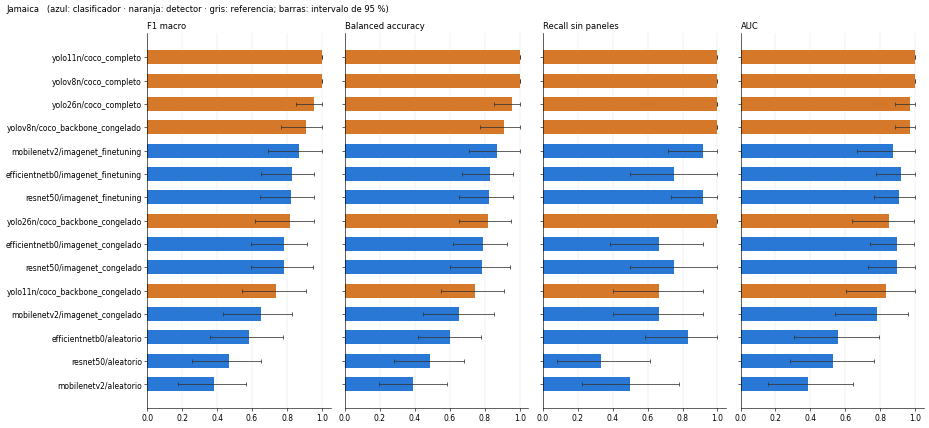

,familia,F1 macro,Balanced accuracy,Recall sin paneles,AUC
corrida,,,,,
yolo11n/coco_completo,detector,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]"
yolov8n/coco_completo,detector,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","1.000 [1.000, 1.000]"
yolo26n/coco_completo,detector,"0.956 [0.852, 1.000]","0.955 [0.850, 1.000]","1.000 [1.000, 1.000]","0.970 [0.885, 1.000]"
yolov8n/coco_backbone_congelado,detector,"0.912 [0.767, 1.000]","0.909 [0.773, 1.000]","1.000 [1.000, 1.000]","0.970 [0.885, 1.000]"
mobilenetv2/imagenet_finetuning,clasificador,"0.869 [0.693, 1.000]","0.867 [0.708, 1.000]","0.917 [0.714, 1.000]","0.871 [0.667, 1.000]"
efficientnetb0/imagenet_finetuning,clasificador,"0.826 [0.652, 0.956]","0.830 [0.669, 0.962]","0.750 [0.500, 1.000]","0.917 [0.777, 1.000]"
resnet50/imagenet_finetuning,clasificador,"0.823 [0.646, 0.956]","0.822 [0.652, 0.962]","0.917 [0.733, 1.000]","0.909 [0.762, 1.000]"
yolo26n/coco_backbone_congelado,detector,"0.817 [0.617, 0.955]","0.818 [0.654, 0.950]","1.000 [1.000, 1.000]","0.848 [0.638, 0.992]"
efficientnetb0/imagenet_congelado,clasificador,"0.781 [0.596, 0.913]","0.788 [0.619, 0.929]","0.667 [0.385, 0.917]","0.894 [0.738, 0.992]"


In [4]:
jamaica = comparacion.intervalos(resultados.cargar_predicciones(rutas), ELEGIDAS, solo_jamaica=True).sort_values(
    ["balanced_accuracy", "roc_auc"], ascending=False, ignore_index=True)
print(f"Jamaica: {jamaica['n'].iloc[0]} imágenes, {jamaica['n_sin_paneles'].iloc[0]} sin paneles.")
graficar(jamaica, "Jamaica")
con_intervalo(jamaica)

## 4. ¿Qué diferencias son claras?

Cada corrida contra la mejor: en val por F1 macro, y en Jamaica por balanced accuracy. `diferencia` es *corrida −
mejor* (negativa = peor). **`clara = True` solo si el intervalo no incluye el 0**: las demás corridas no se pueden
distinguir de la mejor con estos datos.

In [5]:
predicciones = resultados.cargar_predicciones(rutas)
sin_referencia = [c for c in ELEGIDAS if FAMILIA[c] != "referencia"]
mejor_val = val.loc[val["corrida"].isin(sin_referencia), "corrida"].iloc[0]
mejor_jamaica = jamaica.loc[jamaica["corrida"].isin(sin_referencia), "corrida"].iloc[0]
print("Mejor en val (F1 macro):", mejor_val)
display(comparacion.diferencias(predicciones, ELEGIDAS, mejor_val, metrica="f1_macro").round(3))
print("Mejor en Jamaica (balanced accuracy):", mejor_jamaica)
comparacion.diferencias(predicciones, ELEGIDAS, mejor_jamaica, metrica="balanced_accuracy",
                        solo_jamaica=True).round(3)

Mejor en val (F1 macro): yolov8n/coco_completo


,corrida,referencia,metrica,diferencia,inf,sup,clara
0,yolo11n/coco_completo,yolov8n/coco_completo,f1_macro,-0.002,-0.044,0.037,False
1,yolo26n/coco_completo,yolov8n/coco_completo,f1_macro,-0.015,-0.063,0.030,False
2,yolov8n/coco_backbone_congelado,yolov8n/coco_completo,f1_macro,-0.047,-0.121,0.022,False
3,yolo26n/coco_backbone_congelado,yolov8n/coco_completo,f1_macro,-0.087,-0.171,-0.011,True
4,resnet50/imagenet_finetuning,yolov8n/coco_completo,f1_macro,-0.097,-0.181,-0.018,True
5,mobilenetv2/imagenet_finetuning,yolov8n/coco_completo,f1_macro,-0.134,-0.233,-0.049,True
6,yolo11n/coco_backbone_congelado,yolov8n/coco_completo,f1_macro,-0.135,-0.233,-0.052,True
7,efficientnetb0/imagenet_finetuning,yolov8n/coco_completo,f1_macro,-0.166,-0.267,-0.079,True
8,resnet50/imagenet_congelado,yolov8n/coco_completo,f1_macro,-0.174,-0.274,-0.087,True
9,mobilenetv2/imagenet_congelado,yolov8n/coco_completo,f1_macro,-0.239,-0.343,-0.143,True


Mejor en Jamaica (balanced accuracy): yolo11n/coco_completo


,corrida,referencia,metrica,diferencia,inf,sup,clara
0,yolov8n/coco_completo,yolo11n/coco_completo,balanced_accuracy,0.000,0.000,0.000,False
1,yolo26n/coco_completo,yolo11n/coco_completo,balanced_accuracy,-0.045,-0.150,0.000,False
2,yolov8n/coco_backbone_congelado,yolo11n/coco_completo,balanced_accuracy,-0.091,-0.227,0.000,False
3,mobilenetv2/imagenet_finetuning,yolo11n/coco_completo,balanced_accuracy,-0.133,-0.292,0.000,False
4,efficientnetb0/imagenet_finetuning,yolo11n/coco_completo,balanced_accuracy,-0.170,-0.331,-0.038,True
5,resnet50/imagenet_finetuning,yolo11n/coco_completo,balanced_accuracy,-0.178,-0.348,-0.038,True
6,yolo26n/coco_backbone_congelado,yolo11n/coco_completo,balanced_accuracy,-0.182,-0.346,-0.050,True
7,efficientnetb0/imagenet_congelado,yolo11n/coco_completo,balanced_accuracy,-0.212,-0.381,-0.071,True
8,resnet50/imagenet_congelado,yolo11n/coco_completo,balanced_accuracy,-0.216,-0.398,-0.056,True
9,yolo11n/coco_backbone_congelado,yolo11n/coco_completo,balanced_accuracy,-0.258,-0.452,-0.087,True


## 5. Clasificador contra detector usado como clasificador

La pregunta de la consigna: ¿conviene un clasificador o un detector para decir si una imagen tiene paneles? Se
toma el mejor de cada familia en val (por F1 macro) y se comparan pareados, con **AUC** (no depende del umbral) y
con **F1 macro** (cada uno con su umbral: 0.5 la CNN, 0.25 el YOLO).

In [6]:
mejores = {f: val.loc[val["corrida"].map(FAMILIA) == f, "corrida"].iloc[0]
           for f in ("clasificador", "detector") if (val["corrida"].map(FAMILIA) == f).any()}
print("Mejor de cada familia en val:", mejores)
if len(mejores) < 2:
    print("Falta al menos una corrida de cada familia para compararlas.")
else:
    filas = []
    for conjunto, solo_jamaica in (("val", False), ("jamaica", True)):
        for metrica in ("roc_auc", "f1_macro", "balanced_accuracy"):
            d = comparacion.diferencias(predicciones, [mejores["detector"]], mejores["clasificador"],
                                        metrica=metrica, solo_jamaica=solo_jamaica).iloc[0]
            filas.append({"conjunto": conjunto, "metrica": metrica, "detector − clasificador": d["diferencia"],
                          "inf": d["inf"], "sup": d["sup"], "clara": d["clara"]})
    display(pd.DataFrame(filas).round(3))

Mejor de cada familia en val: {'clasificador': 'resnet50/imagenet_finetuning', 'detector': 'yolov8n/coco_completo'}


,conjunto,metrica,detector − clasificador,inf,sup,clara
0,val,roc_auc,0.035,0.002,0.077,True
1,val,f1_macro,0.097,0.018,0.181,True
2,val,balanced_accuracy,0.071,-0.029,0.177,False
3,jamaica,roc_auc,0.091,0.000,0.238,False
4,jamaica,f1_macro,0.177,0.044,0.354,True
5,jamaica,balanced_accuracy,0.178,0.038,0.348,True


## 6. Detección: mAP de los detectores

Métricas de cajas que calcula Ultralytics, sobre val y sobre Jamaica (las guarda cada notebook de detección en
`metricas.json`). No tienen intervalo: son de una sola evaluación.

In [7]:
detectores = [c for c in ELEGIDAS if FAMILIA[c] == "detector"]
deteccion = comparacion.tabla_deteccion(rutas.resultados_equipo, detectores)
if deteccion.empty:
    print("Todavía no hay detectores con métricas de detección guardadas.")
else:
    display(deteccion.pivot(index="corrida", columns="conjunto").round(3))

map50        map50_95        precision  \
conjunto                        jamaica    val  jamaica    val   jamaica   
corrida                                                                    
yolo11n/coco_backbone_congelado   0.514  0.680    0.264  0.336     0.615   
yolo11n/coco_completo             0.718  0.809    0.492  0.512     0.733   
yolo26n/coco_backbone_congelado   0.422  0.734    0.174  0.334     0.510   
yolo26n/coco_completo             0.755  0.883    0.569  0.580     0.860   
yolov8n/coco_backbone_congelado   0.455  0.646    0.238  0.336     0.390   
yolov8n/coco_completo             0.689  0.838    0.403  0.519     0.776   

                                        recall         
conjunto                           val jamaica    val  
corrida                                                
yolo11n/coco_backbone_congelado  0.674   0.571  0.594  
yolo11n/coco_completo            0.768   0.762  0.754  
yolo26n/coco_backbone_congelado  0.695   0.429  0.699  
yolo26n/coco_completo            0.927   0.714  0.772  
yolov8n/coco_backbone_congelado  0.566   0.517  0.683  
yolov8n/coco_completo            0.809   0.667  0.794

## Para el informe

- Decir que **val eligió los checkpoints y también se usó para medir**: los números son optimistas.
- Reportar cada métrica **con su intervalo**, y afirmar que un modelo es mejor solo cuando la diferencia es clara
  (sección 4).
- Comparar CNN contra detector **sobre todo con AUC**, y aclarar que el puntaje de YOLO es la máxima confianza de
  sus cajas, no una probabilidad.
- Jamaica tiene 23 imágenes: indica la tendencia para el test de Kingston, no permite elegir entre modelos
  parecidos.
- Todas las CNN usan la misma receta (sección *Receta común de clasificación* del README) y una sola semilla:
  la variabilidad entre semillas no está medida.